In [1]:
import pandas as pd
df = pd.read_csv("../data/raw/students.csv")
print(df.shape)
print(df["status"].value_counts())
df.head()

(215, 15)
status
Placed        148
Not Placed     67
Name: count, dtype: int64


,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


In [2]:
df.info()
print(df.isna().sum())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    str    
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    str    
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    str    
 6   hsc_s           215 non-null    str    
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    str    
 9   workex          215 non-null    str    
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    str    
 12  mba_p           215 non-null    float64
 13  status          215 non-null    str    
 14  salary          148 non-null    float64
dtypes: float64(6), int64(1), str(8)
memory usage: 35.0 KB
sl_no              0
gender             0
ssc_p              0
ssc_b              

In [3]:
print(df.shape)
print(df["status"].value_counts())

(215, 15)
status
Placed        148
Not Placed     67
Name: count, dtype: int64


In [4]:
df = df.drop(columns=["salary", "sl_no"])
df["placed"] = (df["status"] == "Placed").astype(int)
df = df.drop(columns=["status"])
print(df.shape)
df.head()


(215, 13)


,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,placed
0,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,1
1,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,1
2,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,1
3,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,0
4,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,1


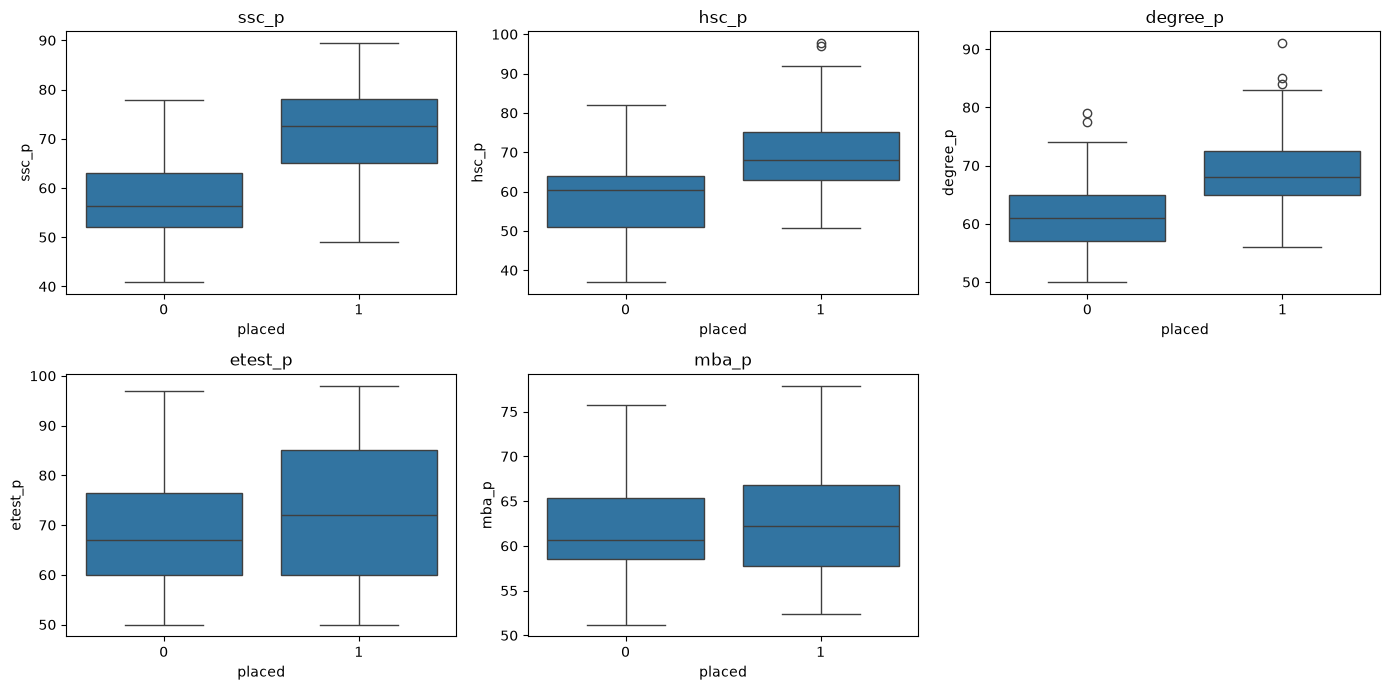

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ["ssc_p", "hsc_p", "degree_p", "etest_p", "mba_p"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x="placed", y=col, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

gender
F    0.63
M    0.72
Name: placed, dtype: float64 

ssc_b
Central    0.67
Others     0.71
Name: placed, dtype: float64 

hsc_b
Central    0.68
Others     0.69
Name: placed, dtype: float64 

hsc_s
Arts        0.55
Commerce    0.70
Science     0.69
Name: placed, dtype: float64 

degree_t
Comm&Mgmt    0.70
Others       0.45
Sci&Tech     0.69
Name: placed, dtype: float64 

workex
No     0.60
Yes    0.86
Name: placed, dtype: float64 

specialisation
Mkt&Fin    0.79
Mkt&HR     0.56
Name: placed, dtype: float64 



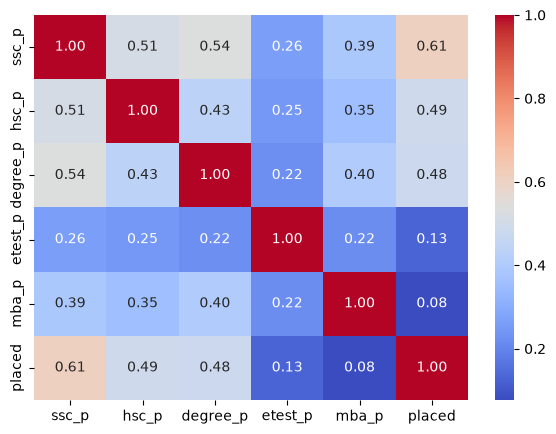

In [6]:
cat_cols = ["gender", "ssc_b", "hsc_b", "hsc_s", "degree_t", "workex", "specialisation"]
for c in cat_cols:
    print(df.groupby(c)["placed"].mean().round(2), "\n")

plt.figure(figsize=(7, 5))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

In [7]:
import numpy as np
rng = np.random.default_rng(42)
n = len(df)

# a hidden "ability" per student, nudged by real academic scores and placement
ability = (
    0.4 * (df["ssc_p"] - df["ssc_p"].mean()) / df["ssc_p"].std()
    + 0.4 * (df["degree_p"] - df["degree_p"].mean()) / df["degree_p"].std()
    + 0.3 * df["placed"]
    + rng.normal(0, 0.6, n)
)

def scale(x, lo, hi):
    z = (x - x.mean()) / x.std()
    return np.clip(lo + (hi - lo) * (0.5 + 0.18 * z), lo, hi)

df["coding_score"] = scale(ability + rng.normal(0, 0.5, n), 20, 100).round(0)
df["communication_score"] = scale(ability + rng.normal(0, 0.7, n), 30, 100).round(0)
df["projects"] = np.clip(np.round(2 + ability + rng.normal(0, 1, n)), 0, 6).astype(int)
df["internships"] = np.clip(np.round(0.8 + 0.5 * ability + rng.normal(0, 0.8, n)), 0, 3).astype(int)
df["certifications"] = np.clip(np.round(2 + ability + rng.normal(0, 1.2, n)), 0, 7).astype(int)

print(df[["coding_score","communication_score","projects","internships","certifications"]].describe().round(1))
print(df.groupby("placed")[["coding_score","projects","internships","certifications"]].mean().round(1))

       coding_score  communication_score  projects  internships  \
count         215.0                215.0     215.0        215.0   
mean           60.0                 65.0       2.2          0.9   
std            14.4                 12.6       1.4          0.8   
min            25.0                 37.0       0.0          0.0   
25%            50.5                 56.0       1.0          0.0   
50%            61.0                 65.0       2.0          1.0   
75%            69.0                 73.0       3.0          1.0   
max            95.0                100.0       6.0          3.0   

       certifications  
count           215.0  
mean              2.2  
std               1.5  
min               0.0  
25%               1.0  
50%               2.0  
75%               3.0  
max               6.0  
        coding_score  projects  internships  certifications
placed                                                     
0               47.8       1.4          0.5             1.5


In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import pandas as pd

X = df.drop(columns=["placed","gender"])
y = df["placed"]

num_cols = X.select_dtypes("number").columns
cat_cols = X.select_dtypes(exclude="number").columns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

models = {
    "LogReg": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, eval_metric="logloss", random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)])
    s = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring=["accuracy", "f1", "roc_auc"])
    rows.append({"model": name,
                 "accuracy": s["test_accuracy"].mean(),
                 "f1": s["test_f1"].mean(),
                 "roc_auc": s["test_roc_auc"].mean()})

print(pd.DataFrame(rows).round(3))

          model  accuracy     f1  roc_auc
0        LogReg     0.843  0.878    0.928
1  RandomForest     0.836  0.878    0.913
2       XGBoost     0.831  0.876    0.916


In [9]:
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

ensemble = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000, class_weight="balanced")),
        ("rf", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)),
        ("xgb", XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                              eval_metric="logloss", random_state=42)),
    ],
    voting="soft",
)

pipe = Pipeline([("prep", prep), ("model", ensemble)])

# cross-validated comparison with the single models
s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"])
print("Ensemble CV:",
      round(s["test_accuracy"].mean(), 3),
      round(s["test_f1"].mean(), 3),
      round(s["test_roc_auc"].mean(), 3))

# fit once, evaluate on the held-out test set
pipe.fit(X_train, y_train)
pred = pipe.predict(X_test)
proba = pipe.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))
print("Test ROC-AUC:", round(roc_auc_score(y_test, proba), 3))

Ensemble CV: 0.848 0.885 0.93
              precision    recall  f1-score   support

           0       0.77      0.77      0.77        13
           1       0.90      0.90      0.90        30

    accuracy                           0.86        43
   macro avg       0.83      0.83      0.83        43
weighted avg       0.86      0.86      0.86        43

[[10  3]
 [ 3 27]]
Test ROC-AUC: 0.959


In [10]:
import numpy as np

# 1. Readiness score = predicted probability of placement, scaled to 0-100
all_proba = pipe.predict_proba(X)[:, 1]
df_out = X.copy()
df_out["readiness_score"] = (all_proba * 100).round(1)
df_out["readiness_level"] = pd.cut(
    df_out["readiness_score"], bins=[-1, 40, 70, 101],
    labels=["Low", "Medium", "High"])
print(df_out["readiness_level"].value_counts())

# 2. Skill-gap: compare a student to the median of High-readiness students
skills = ["ssc_p", "hsc_p", "degree_p", "etest_p", "mba_p",
          "coding_score", "communication_score",
          "projects", "internships", "certifications"]
benchmark = df_out[df_out["readiness_level"] == "High"][skills].median()

def skill_gap(i):
    row = df_out.loc[i, skills]
    gap = (row - benchmark).round(1)
    out = pd.DataFrame({"student": row, "benchmark": benchmark, "gap": gap})
    return out.sort_values("gap")  # most negative gap first = biggest weakness

# example: a Low-readiness student
i = df_out[df_out["readiness_level"] == "Low"].index[0]
print("Student", i, "readiness:", df_out.loc[i, "readiness_score"])
skill_gap(i).head(5)

readiness_level
High      131
Low        60
Medium     24
Name: count, dtype: int64
Student 3 readiness: 2.6


,student,benchmark,gap
communication_score,43.0,69.0,-26.0
coding_score,48.0,67.0,-19.0
hsc_p,52.0,70.0,-18.0
ssc_p,56.0,73.0,-17.0
degree_p,52.0,68.0,-16.0


c:\Users\prani\OneDrive\Desktop\lpu-placement-intelligence\Lpu-Placement-intelligence\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


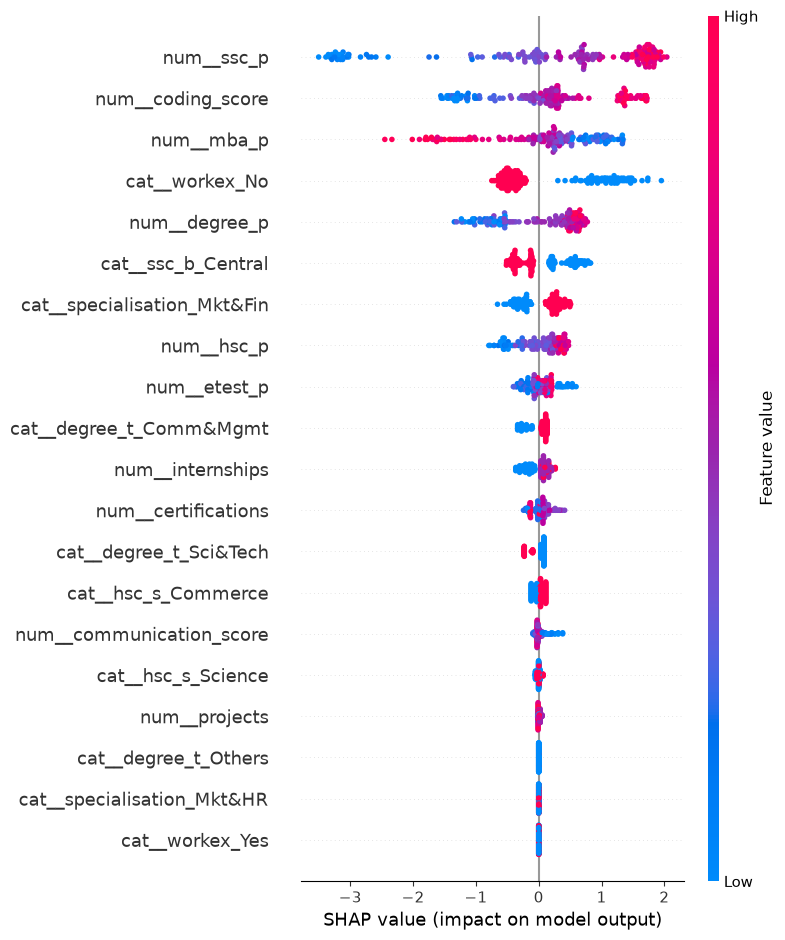

In [11]:
import shap
import matplotlib.pyplot as plt

# use the fitted XGBoost inside the ensemble, on preprocessed data
xgb = pipe.named_steps["model"].named_estimators_["xgb"]
prep_fit = pipe.named_steps["prep"]
Xt = prep_fit.transform(X_train)
feat_names = prep_fit.get_feature_names_out()
Xt_df = pd.DataFrame(Xt.toarray() if hasattr(Xt, "toarray") else Xt, columns=feat_names)

explainer = shap.TreeExplainer(xgb)
sv = explainer.shap_values(Xt_df)

# global: which features matter most overall
shap.summary_plot(sv, Xt_df, show=False)
plt.tight_layout()
plt.show()

In [12]:
Xi = pd.DataFrame(
    (lambda a: a.toarray() if hasattr(a, "toarray") else a)(prep_fit.transform(X.loc[[3]])),
    columns=feat_names)
svi = explainer.shap_values(Xi)[0]
top = pd.Series(svi, index=feat_names).sort_values()
print("Pulling readiness DOWN:\n", top.head(4).round(2))
print("\nPushing readiness UP:\n", top.tail(3).round(2))

Pulling readiness DOWN:
 num__ssc_p       -1.63
num__degree_p    -0.80
num__hsc_p       -0.71
cat__workex_No   -0.58
dtype: float32

Pushing readiness UP:
 num__internships            0.07
num__mba_p                  0.31
num__communication_score    0.31
dtype: float32


In [13]:
import joblib, json
joblib.dump(pipe, "../models/readiness_pipeline.joblib")
benchmark.to_json("../models/benchmark.json")
print("saved")

saved
